In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder,StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

In [2]:
df = pd.read_csv("financial_fraud_monitoring_synthetic.csv")
df

,transaction_id,timestamp,amount,transaction_type,hour,is_night,period,is_fraud
0,TXN000001,2026-01-01 00:00:00,238.47,PAYMENT,0,1,baseline,0
1,TXN000002,2026-01-01 00:13:00,71.09,DEBIT,0,1,baseline,0
2,TXN000003,2026-01-01 00:26:00,356.17,PAYMENT,0,1,baseline,0
3,TXN000004,2026-01-01 00:39:00,422.63,CASH_IN,0,1,baseline,0
4,TXN000005,2026-01-01 00:52:00,31.31,DEBIT,0,1,baseline,0
...,...,...,...,...,...,...,...,...
9995,TXN009996,2026-04-01 05:35:00,1660.42,DEBIT,5,1,drift_period,1
9996,TXN009997,2026-04-01 05:48:00,126.20,PAYMENT,5,1,drift_period,0
9997,TXN009998,2026-04-01 06:01:00,539.86,TRANSFER,6,0,drift_period,0
9998,TXN009999,2026-04-01 06:14:00,483.50,PAYMENT,6,0,drift_period,0


In [3]:
df.head()

,transaction_id,timestamp,amount,transaction_type,hour,is_night,period,is_fraud
0,TXN000001,2026-01-01 00:00:00,238.47,PAYMENT,0,1,baseline,0
1,TXN000002,2026-01-01 00:13:00,71.09,DEBIT,0,1,baseline,0
2,TXN000003,2026-01-01 00:26:00,356.17,PAYMENT,0,1,baseline,0
3,TXN000004,2026-01-01 00:39:00,422.63,CASH_IN,0,1,baseline,0
4,TXN000005,2026-01-01 00:52:00,31.31,DEBIT,0,1,baseline,0


In [4]:
df.shape

(10000, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    10000 non-null  str    
 1   timestamp         10000 non-null  str    
 2   amount            10000 non-null  float64
 3   transaction_type  10000 non-null  str    
 4   hour              10000 non-null  int64  
 5   is_night          10000 non-null  int64  
 6   period            10000 non-null  str    
 7   is_fraud          10000 non-null  int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 1.0 MB


### DATA PREPROCESSING

In [6]:
df.isnull().sum()

transaction_id      0
timestamp           0
amount              0
transaction_type    0
hour                0
is_night            0
period              0
is_fraud            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,amount,hour,is_night,is_fraud
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,348.060508,11.474200,0.335100,0.036100
std,433.638642,6.929656,0.472049,0.186548
min,5.000000,0.000000,0.000000,0.000000
25%,111.752500,5.000000,0.000000,0.000000
50%,213.780000,11.000000,0.000000,0.000000
75%,408.882500,17.000000,1.000000,0.000000
max,6685.900000,23.000000,1.000000,1.000000


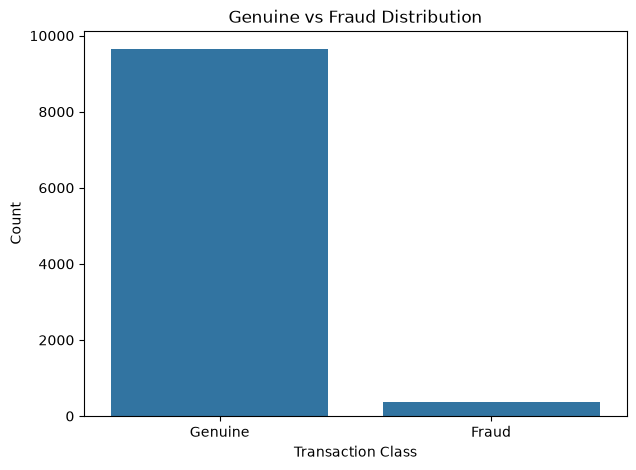

In [9]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='is_fraud')

plt.title('Genuine vs Fraud Distribution')
plt.xlabel('Transaction Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Genuine', 'Fraud'])
plt.show()

In [10]:
df.select_dtypes(include='object').columns

C:\Users\ATHULYA M\AppData\Local\Temp\ipykernel_5204\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['transaction_id', 'timestamp', 'transaction_type', 'period'], dtype='str')

In [11]:
df['is_fraud'].value_counts()

is_fraud
0    9639
1     361
Name: count, dtype: int64

In [12]:
df['transaction_type'].value_counts()

transaction_type
PAYMENT     3077
TRANSFER    2896
CASH_OUT    1719
DEBIT       1376
CASH_IN      932
Name: count, dtype: int64

In [13]:
df['period'].value_counts()

period
baseline        6647
drift_period    3353
Name: count, dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df['is_fraud'].value_counts(normalize=True)*100

is_fraud
0    96.39
1     3.61
Name: proportion, dtype: float64

In [16]:
df['timestamp'].dtype

<StringDtype(na_value=nan)>

In [17]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [18]:
df['timestamp'].dtype

dtype('<M8[us]')

In [19]:
df['date']=df['timestamp'].dt.date
df['hour']=df['timestamp'].dt.hour

In [20]:
df[['timestamp','date','hour']].head()

,timestamp,date,hour
0,2026-01-01 00:00:00,2026-01-01,0
1,2026-01-01 00:13:00,2026-01-01,0
2,2026-01-01 00:26:00,2026-01-01,0
3,2026-01-01 00:39:00,2026-01-01,0
4,2026-01-01 00:52:00,2026-01-01,0


### FEATURE SCALING

In [21]:
le = LabelEncoder()
df['transaction_type_encoded'] = le.fit_transform(df['transaction_type'])

In [22]:
le_period = LabelEncoder()
df['period_encoded'] = le_period.fit_transform(df['period'])

In [23]:
df[['transaction_type', 'transaction_type_encoded','period', 'period_encoded']].head(10)

,transaction_type,transaction_type_encoded,period,period_encoded
0,PAYMENT,3,baseline,0
1,DEBIT,2,baseline,0
2,PAYMENT,3,baseline,0
3,CASH_IN,0,baseline,0
4,DEBIT,2,baseline,0
5,CASH_OUT,1,baseline,0
6,TRANSFER,4,baseline,0
7,PAYMENT,3,baseline,0
8,DEBIT,2,baseline,0
9,TRANSFER,4,baseline,0


In [24]:
df

,transaction_id,timestamp,amount,transaction_type,hour,is_night,period,is_fraud,date,transaction_type_encoded,period_encoded
0,TXN000001,2026-01-01 00:00:00,238.47,PAYMENT,0,1,baseline,0,2026-01-01,3,0
1,TXN000002,2026-01-01 00:13:00,71.09,DEBIT,0,1,baseline,0,2026-01-01,2,0
2,TXN000003,2026-01-01 00:26:00,356.17,PAYMENT,0,1,baseline,0,2026-01-01,3,0
3,TXN000004,2026-01-01 00:39:00,422.63,CASH_IN,0,1,baseline,0,2026-01-01,0,0
4,TXN000005,2026-01-01 00:52:00,31.31,DEBIT,0,1,baseline,0,2026-01-01,2,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN009996,2026-04-01 05:35:00,1660.42,DEBIT,5,1,drift_period,1,2026-04-01,2,1
9996,TXN009997,2026-04-01 05:48:00,126.20,PAYMENT,5,1,drift_period,0,2026-04-01,3,1
9997,TXN009998,2026-04-01 06:01:00,539.86,TRANSFER,6,0,drift_period,0,2026-04-01,4,1
9998,TXN009999,2026-04-01 06:14:00,483.50,PAYMENT,6,0,drift_period,0,2026-04-01,3,1


In [25]:
print(le.classes_)
print(le_period.classes_)

['CASH_IN' 'CASH_OUT' 'DEBIT' 'PAYMENT' 'TRANSFER']
['baseline' 'drift_period']


In [26]:
print(dict(zip(le.classes_, le.transform(le.classes_))))
print(dict(zip(le_period.classes_, le_period.transform(le_period.classes_))))

{'CASH_IN': np.int64(0), 'CASH_OUT': np.int64(1), 'DEBIT': np.int64(2), 'PAYMENT': np.int64(3), 'TRANSFER': np.int64(4)}
{'baseline': np.int64(0), 'drift_period': np.int64(1)}


In [27]:
x = df[['amount', 'transaction_type_encoded','hour', 'is_night']]

In [28]:
y = df['is_fraud']

In [29]:
x

,amount,transaction_type_encoded,hour,is_night
0,238.47,3,0,1
1,71.09,2,0,1
2,356.17,3,0,1
3,422.63,0,0,1
4,31.31,2,0,1
...,...,...,...,...
9995,1660.42,2,5,1
9996,126.20,3,5,1
9997,539.86,4,6,0
9998,483.50,3,6,0


In [30]:
y

0       0
1       0
2       0
3       0
4       0
       ..
9995    1
9996    0
9997    0
9998    0
9999    0
Name: is_fraud, Length: 10000, dtype: int64

In [31]:
x.shape

(10000, 4)

In [32]:
y.shape

(10000,)

In [33]:
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)

In [34]:
x_train

,amount,transaction_type_encoded,hour,is_night
9254,179.20,4,13,0
1561,205.60,4,2,1
1670,167.27,4,1,1
6087,343.89,0,22,1
6669,418.72,1,4,1
...,...,...,...,...
5734,133.95,2,18,0
5191,287.22,3,20,0
5390,768.14,4,15,0
860,74.90,1,18,0


In [35]:
x_test

,amount,transaction_type_encoded,hour,is_night
6252,448.80,1,10,0
4684,101.07,3,6,0
1731,176.31,4,15,0
4742,164.96,4,19,0
4521,241.42,4,19,0
...,...,...,...,...
6412,73.55,4,21,0
8285,790.21,4,19,0
7853,122.91,4,21,0
1095,546.57,4,21,0


In [36]:
scaler = StandardScaler()

In [37]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [38]:
x_train.shape

(8000, 4)

In [39]:
x_test.shape

(2000, 4)

### MODEL BUILDING

In [40]:
model = LogisticRegression()

In [41]:
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [42]:
y_pred = model.predict(x_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

### MODEL EVALUATION

In [43]:
accuracy = accuracy_score(y_test, y_pred)

In [44]:
accuracy

0.9665

In [45]:
precision = precision_score(y_test, y_pred)
precision

0.5

In [46]:
recall = recall_score(y_test, y_pred)
recall

0.05970149253731343

In [47]:
f1 = f1_score(y_test, y_pred)
f1

0.10666666666666667

In [48]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1933
           1       0.50      0.06      0.11        67

    accuracy                           0.97      2000
   macro avg       0.73      0.53      0.54      2000
weighted avg       0.95      0.97      0.95      2000



In [49]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[1929,    4],
       [  63,    4]])

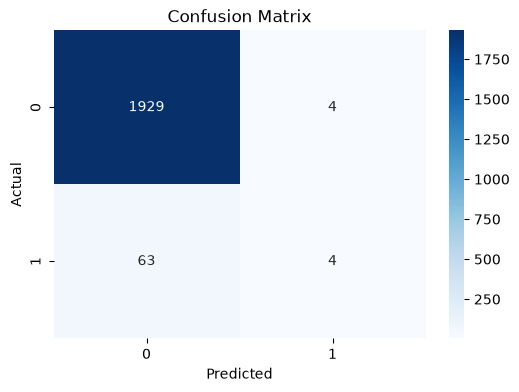

In [50]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### DATA DRIFT DETECTION

In [51]:
print(df['period'].value_counts())

period
baseline        6647
drift_period    3353
Name: count, dtype: int64


In [52]:
df.groupby('period')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
baseline,6647.0,271.390638,301.862979,5.00,98.64,182.12,325.695,4058.8
drift_period,3353.0,500.051151,587.791913,7.03,152.21,308.98,603.900,6685.9


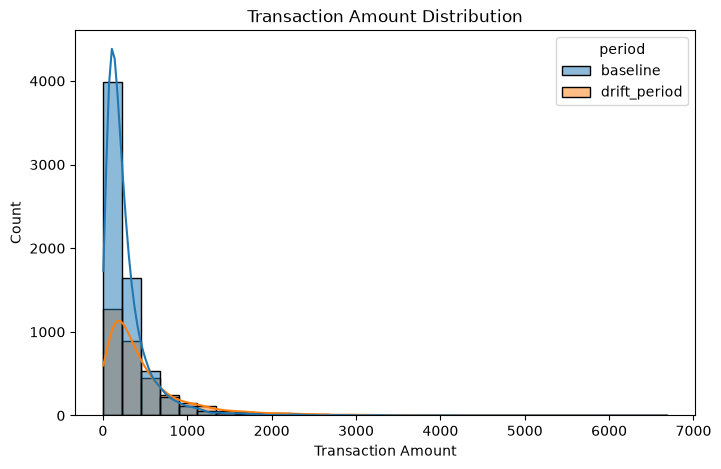

In [53]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df,x='amount',hue='period',bins=30,kde=True)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Count")
plt.show()

In [54]:
df.groupby(['period', 'transaction_type']).size().unstack(fill_value=0)

transaction_type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
period,,,,,
baseline,767,964,955,2327,1634
drift_period,165,755,421,750,1262


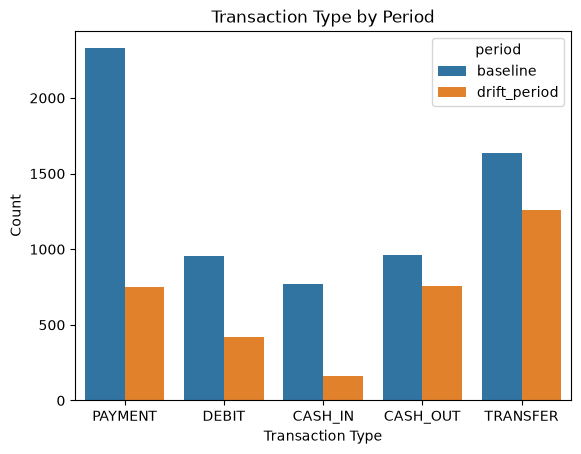

In [55]:
sns.countplot(data=df, x='transaction_type', hue='period')
plt.title("Transaction Type by Period")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

In [56]:
baseline = df[df['period'] == 'baseline']
drift = df[df['period'] == 'drift_period']

In [57]:
print("Baseline Average:", baseline['amount'].mean())
print("Drift Period Average:", drift['amount'].mean())

Baseline Average: 271.39063788175116
Drift Period Average: 500.05115120787354


In [58]:
old_value = baseline['amount'].mean()
new_value = drift['amount'].mean()

difference = ((new_value - old_value) / old_value) * 100
print("Percentage Difference:", difference)

Percentage Difference: 84.2551221040105


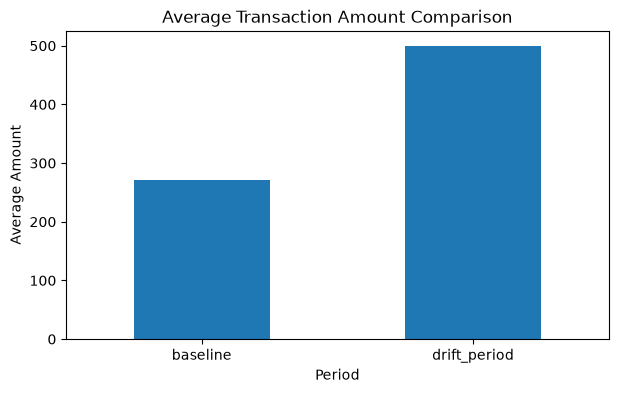

In [59]:
average_amount = df.groupby('period')['amount'].mean()
average_amount.plot(kind='bar', figsize=(7, 4))

plt.title("Average Transaction Amount Comparison")
plt.xlabel("Period")
plt.ylabel("Average Amount")
plt.xticks([0, 1], ['baseline', 'drift_period'], rotation=0)
plt.show()

### MODEL PERFORMANCE MONITORING

In [60]:
results = pd.DataFrame({'Actual': y_test.values,'Predicted': y_pred})
results.head(10)

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [61]:
results['Correct'] = results['Actual'] == results['Predicted']
results.head(10)

,Actual,Predicted,Correct
0,0,0,True
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


In [62]:
print("Correct Predictions:", results['Correct'].sum())
print("Wrong Predictions:", (~results['Correct']).sum())
print("Total Predictions:", len(results))

Correct Predictions: 1933
Wrong Predictions: 67
Total Predictions: 2000


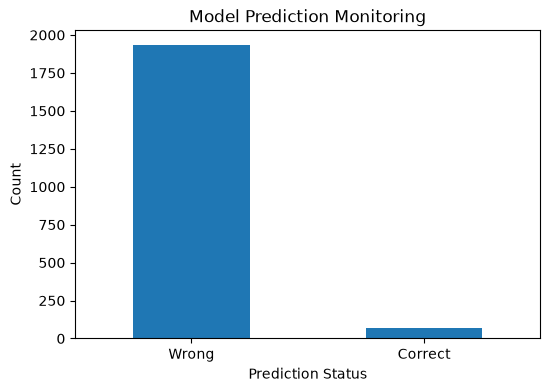

In [63]:
results['Correct'].value_counts().plot(kind='bar',figsize=(6, 4))

plt.title("Model Prediction Monitoring")
plt.xlabel("Prediction Status")
plt.ylabel("Count")
plt.xticks([0, 1], ['Wrong', 'Correct'], rotation=0)
plt.show()

In [64]:
print("Actual Fraud:", (results['Actual'] == 1).sum())
print("Detected Fraud:",((results['Actual'] == 1) & (results['Predicted'] == 1)).sum())
print("Missed Fraud:",((results['Actual'] == 1) & (results['Predicted'] == 0)).sum())

Actual Fraud: 67
Detected Fraud: 4
Missed Fraud: 63


In [65]:
_, test_indices = train_test_split(df.index,test_size=0.2,random_state=42)

In [66]:
results = pd.DataFrame({'Actual': y_test,'Predicted': y_pred})
results['Period'] = df.loc[test_indices, 'period']
results.head()

,Actual,Predicted,Period
6252,0,0,baseline
4684,0,0,baseline
1731,0,0,baseline
4742,0,0,baseline
4521,0,0,baseline


In [67]:
results = pd.DataFrame({'Actual': y_test,'Predicted': y_pred})

results['Period'] = df.loc[test_indices, 'period'].values
results.head()

,Actual,Predicted,Period
6252,0,0,baseline
4684,0,0,baseline
1731,0,0,baseline
4742,0,0,baseline
4521,0,0,baseline


In [68]:
results['Correct'] = results['Actual'] == results['Predicted']

period_accuracy = results.groupby('Period')['Correct'].mean() * 100
print(period_accuracy)

Period
baseline        97.754491
drift_period    94.427711
Name: Correct, dtype: float64


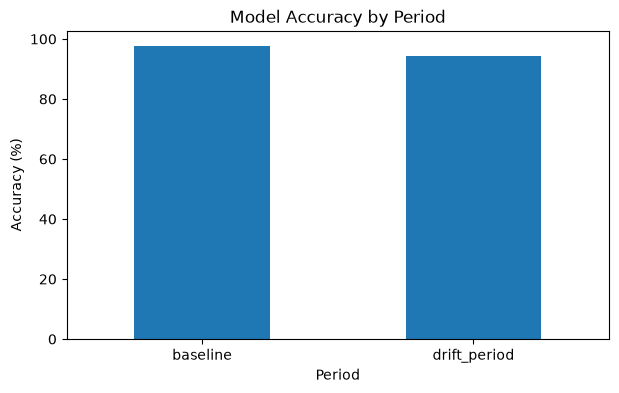

In [69]:
period_accuracy.plot(kind='bar', figsize=(7, 4))

plt.title("Model Accuracy by Period")
plt.xlabel("Period")
plt.ylabel("Accuracy (%)")
plt.xticks([0, 1], ['baseline', 'drift_period'], rotation=0)
plt.show()

In [70]:
for period in results['Period'].unique():
    data = results[results['Period'] == period]
    recall = recall_score(data['Actual'],data['Predicted'],zero_division=0)
    print(period, "Recall:", recall)

baseline Recall: 0.0
drift_period Recall: 0.10526315789473684


### MODEL IMPROVEMENT

In [71]:
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

In [72]:
rf_model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [73]:
rf_pred = rf_model.predict(x_test)

In [74]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1933
           1       0.30      0.13      0.19        67

    accuracy                           0.96      2000
   macro avg       0.64      0.56      0.58      2000
weighted avg       0.95      0.96      0.95      2000



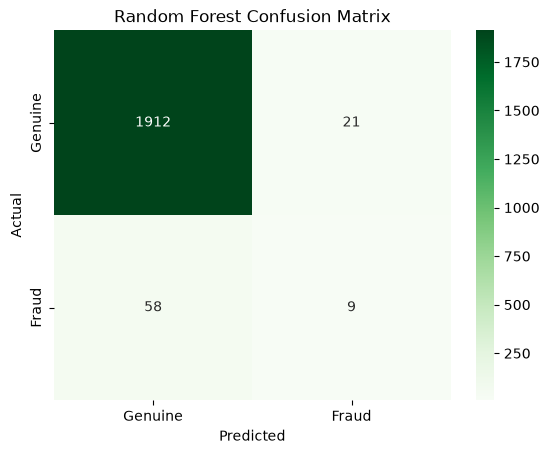

In [75]:
rf_cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(rf_cm,annot=True,fmt='d',cmap='Greens',xticklabels=['Genuine', 'Fraud'],yticklabels=['Genuine', 'Fraud'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [76]:
print("Logistic Regression Recall:",recall_score(y_test, y_pred))
print("Random Forest Recall:",recall_score(y_test, rf_pred))

Logistic Regression Recall: 0.05970149253731343
Random Forest Recall: 0.13432835820895522


### THRESHOLD TUNING

In [77]:
rf_probability = rf_model.predict_proba(x_test)[:, 1]

In [78]:
rf_pred_new = (rf_probability >= 0.3).astype(int)

In [79]:
print("Old Recall:",recall_score(y_test, rf_pred))

print("New Recall:",recall_score(y_test, rf_pred_new))

print("New Precision:",precision_score(y_test, rf_pred_new, zero_division=0))

Old Recall: 0.13432835820895522
New Recall: 0.16417910447761194
New Precision: 0.14102564102564102


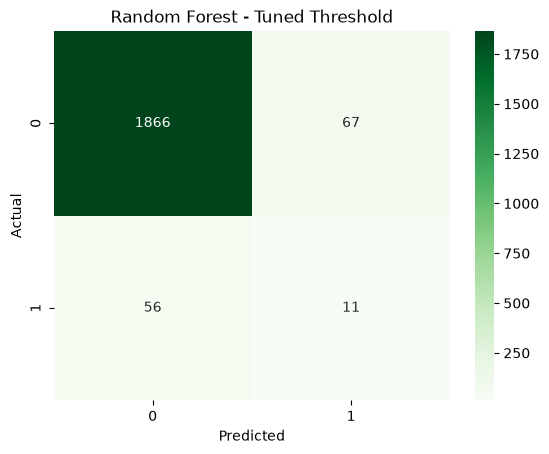

In [80]:
new_cm = confusion_matrix(y_test, rf_pred_new)
sns.heatmap(new_cm, annot=True, fmt='d', cmap='Greens')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Tuned Threshold")
plt.show()

In [81]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:

    predictions = (rf_probability >= threshold).astype(int)

    recall = recall_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)

    print("Threshold:", threshold)
    print("Recall:", recall)
    print("Precision:", precision)
    print("-------------------")

Threshold: 0.1
Recall: 0.22388059701492538
Precision: 0.08241758241758242
-------------------
Threshold: 0.2
Recall: 0.16417910447761194
Precision: 0.10784313725490197
-------------------
Threshold: 0.3
Recall: 0.16417910447761194
Precision: 0.14102564102564102
-------------------
Threshold: 0.4
Recall: 0.13432835820895522
Precision: 0.1875
-------------------
Threshold: 0.5
Recall: 0.13432835820895522
Precision: 0.2647058823529412
-------------------


In [82]:
x = df[['amount', 'transaction_type', 'hour', 'is_night']]
y = df['is_fraud']

In [83]:
x = pd.get_dummies(x,columns=['transaction_type'],dtype=int)

In [84]:
x.head()

,amount,hour,is_night,transaction_type_CASH_IN,transaction_type_CASH_OUT,transaction_type_DEBIT,transaction_type_PAYMENT,transaction_type_TRANSFER
0,238.47,0,1,0,0,0,1,0
1,71.09,0,1,0,0,1,0,0
2,356.17,0,1,0,0,0,1,0
3,422.63,0,1,1,0,0,0,0
4,31.31,0,1,0,0,1,0,0


In [85]:
print("Features shape:", x.shape)

Features shape: (10000, 8)


In [86]:
x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)

In [87]:
smote = SMOTENC(categorical_features=[1],random_state=42)

In [88]:
x_train_resampled, y_train_resampled = smote.fit_resample(x_train,y_train)

In [89]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
is_fraud
0    7706
1     294
Name: count, dtype: int64

After SMOTE:
is_fraud
0    7706
1    7706
Name: count, dtype: int64


In [90]:
x_test_encoded = x_test.reindex(columns=x_train_resampled.columns,fill_value=0)

In [91]:
print(x_train_resampled.shape)
print(x_test_encoded.shape)

print(list(x_train_resampled.columns) == list(x_test_encoded.columns))

(15412, 8)
(2000, 8)
True


In [92]:
rf_improved = RandomForestClassifier(n_estimators=100,random_state=42)
rf_improved.fit(x_train_resampled, y_train_resampled)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [93]:
improved_pred = rf_improved.predict(x_test_encoded)

In [94]:
print(classification_report(y_test,improved_pred))

              precision    recall  f1-score   support

           0       0.97      0.96      0.96      1933
           1       0.10      0.13      0.12        67

    accuracy                           0.93      2000
   macro avg       0.54      0.55      0.54      2000
weighted avg       0.94      0.93      0.94      2000



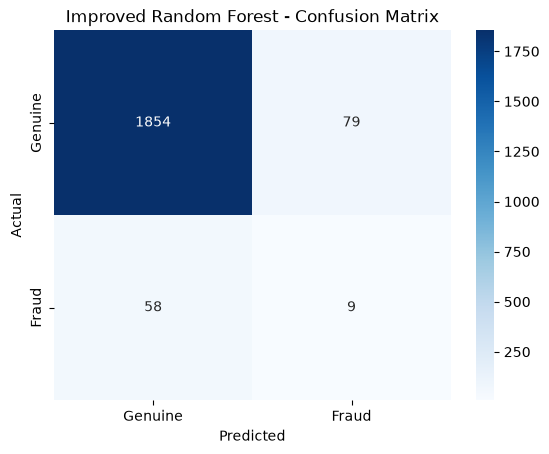

In [95]:
cm = confusion_matrix(y_test, improved_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine', 'Fraud'],
            yticklabels=['Genuine', 'Fraud'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Improved Random Forest - Confusion Matrix')
plt.show()

In [96]:
improved_probability = rf_improved.predict_proba(x_test_encoded)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:

    predictions = (improved_probability >= threshold).astype(int)

    recall = recall_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)

    print("Threshold:", threshold)
    print("Recall:", recall)
    print("Precision:", precision)
    print("--------------------")

Threshold: 0.1
Recall: 0.3582089552238806
Precision: 0.07643312101910828
--------------------
Threshold: 0.2
Recall: 0.208955223880597
Precision: 0.06698564593301436
--------------------
Threshold: 0.3
Recall: 0.1791044776119403
Precision: 0.0821917808219178
--------------------
Threshold: 0.4
Recall: 0.16417910447761194
Precision: 0.09243697478991597
--------------------
Threshold: 0.5
Recall: 0.13432835820895522
Precision: 0.1
--------------------


In [97]:
print(x_train_resampled.columns.tolist())

['amount', 'hour', 'is_night', 'transaction_type_CASH_IN', 'transaction_type_CASH_OUT', 'transaction_type_DEBIT', 'transaction_type_PAYMENT', 'transaction_type_TRANSFER']


In [98]:
print(x_train_resampled.head())

   amount  hour  is_night  transaction_type_CASH_IN  \
0  179.20    13         0                         0   
1  205.60     2         1                         0   
2  167.27     1         1                         0   
3  343.89    22         1                         1   
4  418.72     4         1                         0   

   transaction_type_CASH_OUT  transaction_type_DEBIT  \
0                          0                       0   
1                          0                       0   
2                          0                       0   
3                          0                       0   
4                          1                       0   

   transaction_type_PAYMENT  transaction_type_TRANSFER  
0                         0                          1  
1                         0                          1  
2                         0                          1  
3                         0                          0  
4                         0                    

In [99]:
print(x_test.columns.tolist())

['amount', 'hour', 'is_night', 'transaction_type_CASH_IN', 'transaction_type_CASH_OUT', 'transaction_type_DEBIT', 'transaction_type_PAYMENT', 'transaction_type_TRANSFER']


In [100]:
x_train_encoded=x_train_resampled.copy()
x_test_encoded=x_test.copy()
x_test_encoded=x_test_encoded.reindex(columns=x_train_encoded.columns,fill_value=0)

In [101]:
print(x_train_encoded.shape)
print(x_test_encoded.shape)
print(x_train_encoded.columns.equals(x_test_encoded.columns))

(15412, 8)
(2000, 8)
True


In [102]:
rf_smote_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_smote_model.fit(x_train_encoded, y_train_resampled)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [103]:
smote_predictions = rf_smote_model.predict(x_test_encoded)

In [104]:
print(classification_report(y_test,smote_predictions,target_names=['Genuine','Fraud']))

              precision    recall  f1-score   support

     Genuine       0.97      0.96      0.96      1933
       Fraud       0.10      0.13      0.12        67

    accuracy                           0.93      2000
   macro avg       0.54      0.55      0.54      2000
weighted avg       0.94      0.93      0.94      2000



In [105]:
smote_probability=rf_smote_model.predict_proba(x_test_encoded)[:,1]
print(smote_probability[:10])

[0.54 0.   0.   0.02 0.31 0.06 0.01 0.   0.   0.55]


In [106]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]
for threshold in thresholds:
    predictions = (smote_probability >=threshold). astype(int)
    recall = recall_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)

    print("Threshold:", threshold)
    print("Recall:", recall)
    print("Precision:", precision)
    print("--------------------")

Threshold: 0.1
Recall: 0.3582089552238806
Precision: 0.07643312101910828
--------------------
Threshold: 0.2
Recall: 0.208955223880597
Precision: 0.06698564593301436
--------------------
Threshold: 0.3
Recall: 0.1791044776119403
Precision: 0.0821917808219178
--------------------
Threshold: 0.4
Recall: 0.16417910447761194
Precision: 0.09243697478991597
--------------------
Threshold: 0.5
Recall: 0.13432835820895522
Precision: 0.1
--------------------


In [107]:
final_predictions = (rf_probability >= 0.1).astype(int)

In [108]:
smote_predictions = (smote_probability >= 0.5).astype(int)

In [109]:
print("Previous Model Recall:", recall_score(y_test, final_predictions))
print("SMOTENC Model Recall:", recall_score(y_test, predictions))

Previous Model Recall: 0.22388059701492538
SMOTENC Model Recall: 0.13432835820895522


In [110]:
print(classification_report(y_test,smote_predictions,target_names=['Genuine','Fraud']))

              precision    recall  f1-score   support

     Genuine       0.97      0.96      0.96      1933
       Fraud       0.10      0.13      0.11        67

    accuracy                           0.93      2000
   macro avg       0.53      0.55      0.54      2000
weighted avg       0.94      0.93      0.94      2000



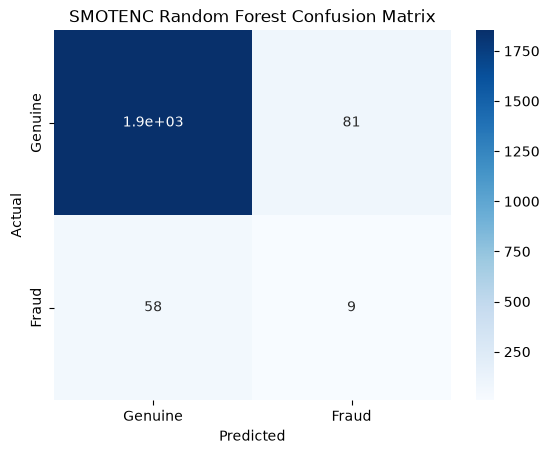

In [111]:
cm = confusion_matrix(y_test, smote_predictions)

sns.heatmap(cm,annot=True,cmap='Blues',xticklabels=['Genuine', 'Fraud'],yticklabels=['Genuine', 'Fraud'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SMOTENC Random Forest Confusion Matrix')
plt.show()

In [112]:
print("PREVIOUS MODEL")
print("Recall:", recall_score(y_test, final_predictions))
print("Precision:", precision_score(y_test, final_predictions, zero_division=0))

print("\nSMOTENC IMPROVED MODEL")
print("Recall:", recall_score(y_test, smote_predictions))
print("Precision:", precision_score(y_test, smote_predictions, zero_division=0))

PREVIOUS MODEL
Recall: 0.22388059701492538
Precision: 0.08241758241758242

SMOTENC IMPROVED MODEL
Recall: 0.13432835820895522
Precision: 0.1


In [113]:
previous_recall = recall_score(y_test, final_predictions)
improved_recall = recall_score(y_test, smote_predictions)

previous_precision = precision_score(y_test, final_predictions, zero_division=0)
improved_precision = precision_score(y_test, smote_predictions, zero_division=0)

comparison = pd.DataFrame({
    'Model': ['Previous Random Forest', 'SMOTENC Random Forest'],
    'Recall': [previous_recall, improved_recall],
    'Precision': [previous_precision, improved_precision]})

print(comparison)

                    Model    Recall  Precision
0  Previous Random Forest  0.223881   0.082418
1   SMOTENC Random Forest  0.134328   0.100000


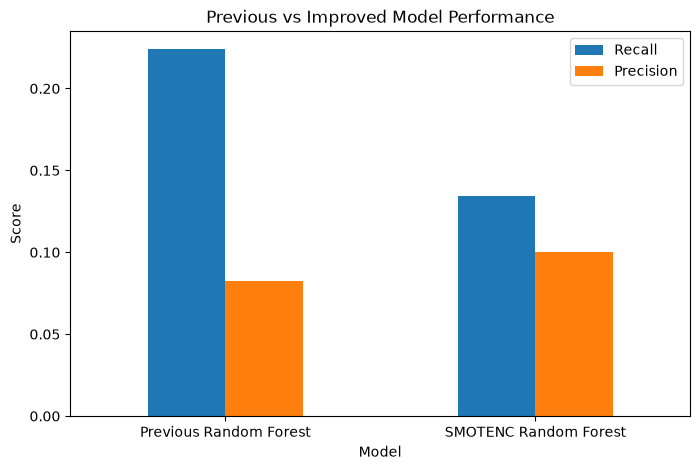

In [114]:
comparison.set_index('Model').plot(kind='bar',figsize=(8, 5))

plt.title('Previous vs Improved Model Performance')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [115]:
print("FINANCIAL FRAUD DETECTION MODEL MONITORING")
print("------------------------------------------")

print("Total Test Transactions:", len(y_test))
print("Actual Fraud Transactions:", sum(y_test == 1))

print("Detected Fraud Transactions:",sum((y_test == 1) & (smote_predictions == 1)))
print("Missed Fraud Transactions:",sum((y_test == 1) & (smote_predictions == 0)))
print("False Fraud Alerts:",sum((y_test == 0) & (smote_predictions == 1)))

FINANCIAL FRAUD DETECTION MODEL MONITORING
------------------------------------------
Total Test Transactions: 2000
Actual Fraud Transactions: 67
Detected Fraud Transactions: 9
Missed Fraud Transactions: 58
False Fraud Alerts: 81


### SAVE THE IMPROVED MODEL

In [116]:
import joblib

In [117]:
joblib.dump(rf_smote_model,'financial_fraud_model.pkl')

['financial_fraud_model.pkl']

In [118]:
joblib.dump(x_train_encoded.columns.tolist(),'model_features.pkl')

['model_features.pkl']

In [119]:
import os

print(os.path.exists('financial_fraud_model.pkl'))
print(os.path.exists('model_features.pkl'))

True
True


In [120]:
loaded_model = joblib.load('financial_fraud_model.pkl')

In [121]:
prediction = loaded_model.predict(x_test_encoded)

In [122]:
new_transaction = pd.DataFrame({'amount': [15000],'hour': [23],'is_night': [1],'transaction_type_CASH_IN': [0],
    'transaction_type_CASH_OUT': [0],'transaction_type_DEBIT': [0],'transaction_type_PAYMENT': [0],'transaction_type_TRANSFER': [1]})

In [123]:
new_transaction = new_transaction.reindex(columns=x_train_encoded.columns,fill_value=0)

In [124]:
new_probability = rf_smote_model.predict_proba(new_transaction)[:, 1]
print("Fraud Probability:", new_probability[0])

Fraud Probability: 0.84


In [125]:
threshold = 0.5

if new_probability[0] >= threshold:
    print("Transaction Status: FRAUD")
else:
    print("Transaction Status: GENUINE")

Transaction Status: FRAUD


In [126]:
from sklearn.metrics import recall_score, precision_score

model_recall = recall_score(y_test, smote_predictions)
model_precision = precision_score(y_test, smote_predictions, zero_division=0)

print("Model Recall:", model_recall)
print("Model Precision:", model_precision)

if model_recall < 0.70:
    print("ALERT: Fraud detection recall is low!")
else:
    print("Model Recall Status: GOOD")

Model Recall: 0.13432835820895522
Model Precision: 0.1
ALERT: Fraud detection recall is low!


In [127]:
if abs(difference) > 20:
    print("ALERT: Data Drift Detected!")
else:
    print("Data Status: No Significant Drift")
    
print("Amount Change:", round(difference, 2), "%")

ALERT: Data Drift Detected!
Amount Change: 84.26 %


In [128]:
if model_recall < 0.70 or abs(difference) > 20:
    monitoring_status = "WARNING"
else:
    monitoring_status = "NORMAL"

print("================================")
print(" FINANCIAL FRAUD MODEL MONITORING")
print("================================")

print("Model Recall:", round(model_recall, 2))
print("Model Precision:", round(model_precision, 2))
print("Amount Change:", round(difference, 2), "%")

print("--------------------------------")
print("FINAL MONITORING STATUS:", monitoring_status)
print("--------------------------------")

 FINANCIAL FRAUD MODEL MONITORING
Model Recall: 0.13
Model Precision: 0.1
Amount Change: 84.26 %
--------------------------------
FINAL MONITORING STATUS: WARNING
--------------------------------


In [129]:
model_artifacts = {'model': rf_smote_model,'features': x_train_encoded.columns.tolist(),'threshold': 0.5}
joblib.dump(model_artifacts,'financial_fraud_monitoring_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [130]:
loaded_artifacts = joblib.load('financial_fraud_monitoring_model.pkl')

loaded_model = loaded_artifacts['model']
saved_features = loaded_artifacts['features']
saved_threshold = loaded_artifacts['threshold']

print("Model loaded successfully!")
print("Saved Features:", saved_features)
print("Saved Threshold:", saved_threshold)

Model loaded successfully!
Saved Features: ['amount', 'hour', 'is_night', 'transaction_type_CASH_IN', 'transaction_type_CASH_OUT', 'transaction_type_DEBIT', 'transaction_type_PAYMENT', 'transaction_type_TRANSFER']
Saved Threshold: 0.5


In [131]:
loaded_predictions = loaded_model.predict(x_test_encoded)
print("Predictions:", loaded_predictions[:10])
print("Model loaded and prediction completed!")

Predictions: [1 0 0 0 0 0 0 0 0 1]
Model loaded and prediction completed!


In [132]:
monitoring_summary = pd.DataFrame({'Metric': [
        'Model Recall',
        'Model Precision',
        'Average Amount Change (%)',
        'Monitoring Status'
    ],
    'Value': [
        model_recall,
        model_precision,
        difference,
        monitoring_status
    ]
})

print(monitoring_summary)

                      Metric      Value
0               Model Recall   0.134328
1            Model Precision        0.1
2  Average Amount Change (%)  84.255122
3          Monitoring Status    WARNING


In [133]:
monitoring_summary.to_csv('financial_fraud_monitoring_report.csv',index=False)
print("Monitoring report saved successfully!")

Monitoring report saved successfully!


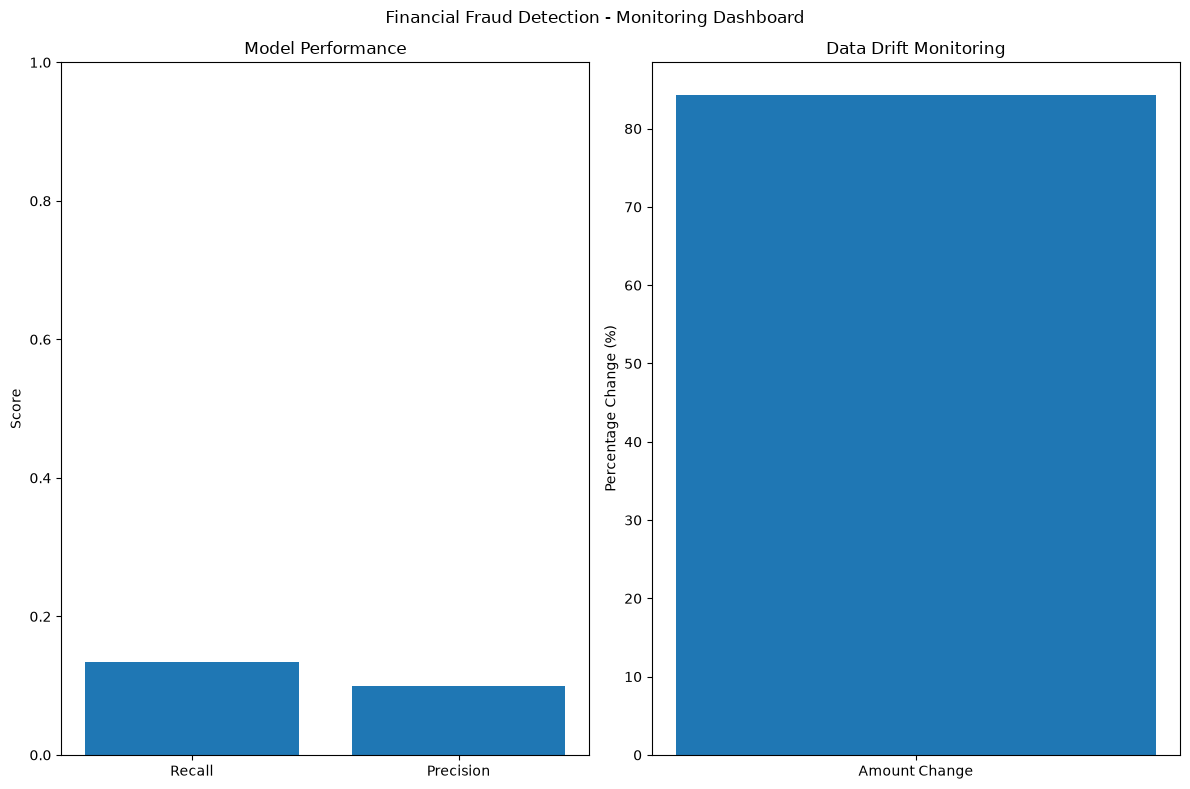

In [134]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

# Model Performance
axes[0].bar(['Recall', 'Precision'],[model_recall, model_precision])
axes[0].set_title('Model Performance')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1)

# Data Drift
axes[1].bar(['Amount Change'],[difference])
axes[1].set_title('Data Drift Monitoring')
axes[1].set_ylabel('Percentage Change (%)')

plt.suptitle('Financial Fraud Detection - Monitoring Dashboard')
plt.tight_layout()

plt.savefig('final_monitoring_dashboard.png')
plt.show()

FINAL MODEL EVALUATION
              precision    recall  f1-score   support

     Genuine       0.97      0.96      0.96      1933
       Fraud       0.10      0.13      0.12        67

    accuracy                           0.93      2000
   macro avg       0.54      0.55      0.54      2000
weighted avg       0.94      0.93      0.94      2000



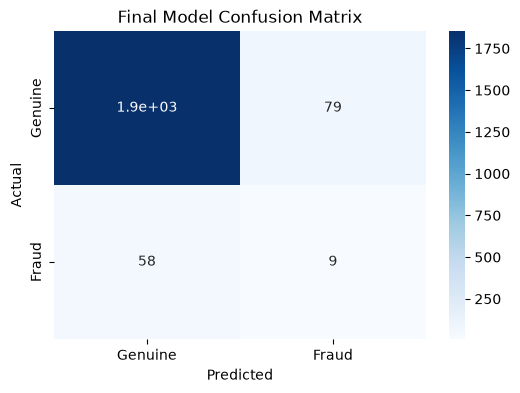

In [135]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("FINAL MODEL EVALUATION")

print(classification_report(y_test,loaded_predictions,target_names=['Genuine', 'Fraud'],zero_division=0))

cm = confusion_matrix(y_test, loaded_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm,annot=True,cmap='Blues',xticklabels=['Genuine', 'Fraud'],yticklabels=['Genuine', 'Fraud'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Model Confusion Matrix")
plt.show()

In [136]:
feature_importance = pd.DataFrame({'Feature': saved_features,'Importance': loaded_model.feature_importances_})
feature_importance = feature_importance.sort_values(by='Importance',ascending=False)
print(feature_importance)

                     Feature  Importance
0                     amount    0.328569
6   transaction_type_PAYMENT    0.146119
1                       hour    0.138430
7  transaction_type_TRANSFER    0.092325
4  transaction_type_CASH_OUT    0.090973
5     transaction_type_DEBIT    0.090877
3   transaction_type_CASH_IN    0.078630
2                   is_night    0.034076


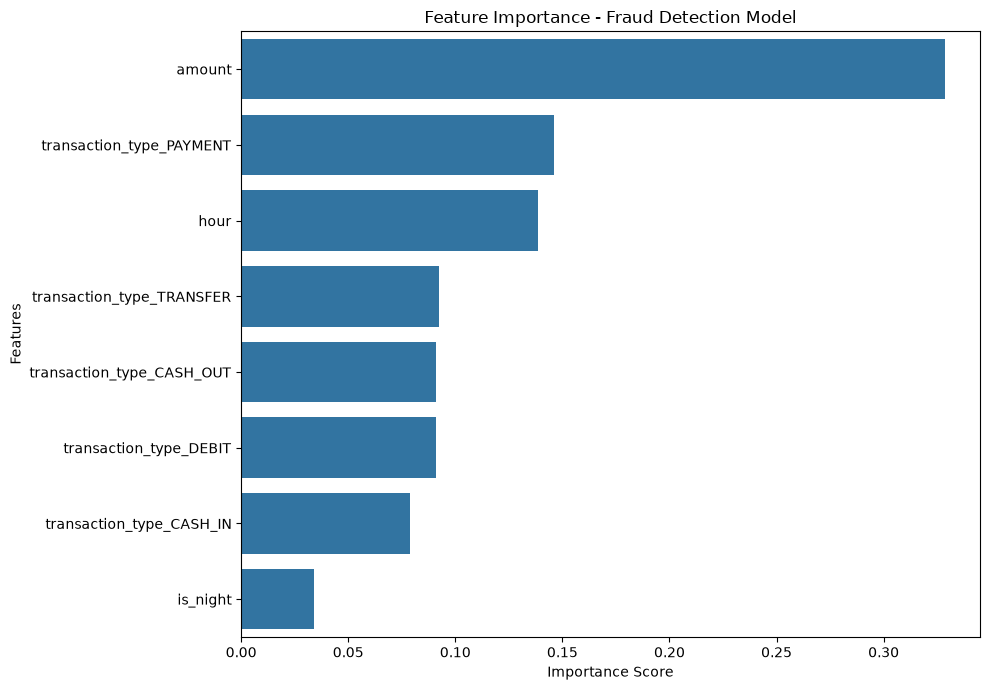

In [137]:
plt.figure(figsize=(10, 7))

sns.barplot(data=feature_importance,x='Importance',y='Feature')

plt.title('Feature Importance - Fraud Detection Model')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()

plt.savefig('feature_importance.png')
plt.show()

In [138]:
feature_importance.to_csv('feature_importance_results.csv',index=False)
print("Feature importance results saved successfully!")

Feature importance results saved successfully!


In [139]:
required_files = ['financial_fraud_monitoring_model.pkl',
    'financial_fraud_monitoring_report.csv','final_monitoring_dashboard.png',
    'feature_importance.png','feature_importance_results.csv']

for file in required_files:
    if os.path.exists(file):
        print(file, "- Available")
    else:
        print(file, "- Missing")

financial_fraud_monitoring_model.pkl - Available
financial_fraud_monitoring_report.csv - Available
final_monitoring_dashboard.png - Available
feature_importance.png - Available
feature_importance_results.csv - Available


In [140]:
print("==========================================")
print(" FINANCIAL FRAUD DETECTION & MONITORING")
print("==========================================")

print("Dataset Size:", df.shape)
print("Total Transactions:", len(df))
print("Actual Fraud Cases:", int(df['is_fraud'].sum()))

print("\n--- MODEL DETAILS ---")
print("Algorithm: Random Forest")
print("Imbalance Handling: SMOTENC")
print("Model Recall:", round(model_recall, 4))
print("Model Precision:", round(model_precision, 4))

print("\n--- DRIFT MONITORING ---")
print("Average Amount Change:", round(difference, 2), "%")

print("\n--- FINAL STATUS ---")
print("Monitoring Status:", monitoring_status)

print("\nProject Coding Summary Generated!")

 FINANCIAL FRAUD DETECTION & MONITORING
Dataset Size: (10000, 11)
Total Transactions: 10000
Actual Fraud Cases: 361

--- MODEL DETAILS ---
Algorithm: Random Forest
Imbalance Handling: SMOTENC
Model Recall: 0.1343
Model Precision: 0.1

--- DRIFT MONITORING ---
Average Amount Change: 84.26 %

--- FINAL STATUS ---
Monitoring Status: WARNING

Project Coding Summary Generated!
